# Normal samples from LLM flips: calibration and the CLT

Target: **2,000 samples with mean 10 and standard deviation 2**, each obtained from 40 fresh LLM responses in $\{-1,1\}$. This notebook analyzes recorded calls; it never sends API requests or generates substitute random data. Rerun it after collection finishes to refresh the results.

The model, prompt, settings, provider metadata, retries, invalid responses, and immutable group indices are retained. Calls have separate conversations. That design does **not prove independence** or a stable response distribution. The normal approximation, calibration uncertainty, and diagnostics below are conditional on these assumptions.

Public copy: original numerical replies and grouping are preserved. Provider URLs, private paths, and transport-error details are omitted; public file hashes are recomputed. Run `python prepare_data.py` from the repository root before executing this notebook. See the root README for provenance and reproduction steps.

In [1]:
from pathlib import Path
import hashlib
import json
import math
import numpy as np
import pandas as pd
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

# Works from this notebook's directory, repository root, or experiment directory.
locations = [Path.cwd() / 'llm_randomness',
             Path.cwd() / 'notebooks/llm_randomness', Path.cwd()]
ROOT = next((p for p in locations if (p / 'PLAN.md').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Run from the repository root or python/notebooks.')
DATA = ROOT / 'data'
manifest_path = DATA / 'manifest.json'
manifest = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}

def read_records(path):
    if not path.exists():
        return []
    lines = path.read_text().splitlines()
    records = []
    for index, line in enumerate(lines):
        if not line.strip():
            continue
        try:
            records.append(json.loads(line))
        except json.JSONDecodeError:
            if index == len(lines) - 1:
                print(f'Incomplete final line in {path.name}; refresh after collection.')
            else:
                raise
    return records

columns = ['request_id', 'phase', 'prompt_id', 'prompt', 'group_id', 'position',
           'planned_index', 'raw_response', 'value', 'valid', 'status', 'provider_response_id',
           'model', 'system_fingerprint', 'started_at_utc', 'finished_at_utc',
           'elapsed_seconds', 'usage']
raw = pd.DataFrame(read_records(DATA / 'responses.jsonl')).reindex(columns=columns)
attempts = pd.DataFrame(read_records(DATA / 'attempts.jsonl'))
assert not raw.request_id.duplicated().any(), 'Duplicate terminal request IDs.'
raw['valid'] = raw.valid.fillna(False).astype(bool)
raw['value'] = pd.to_numeric(raw.value, errors='coerce')
raw['group_id'] = pd.to_numeric(raw.group_id, errors='coerce')
raw['position'] = pd.to_numeric(raw.position, errors='coerce')
raw['planned_index'] = pd.to_numeric(raw.planned_index, errors='coerce')
raw['parsed_binary_valid'] = raw.valid & raw.value.isin([-1, 1])
print(f'Snapshot: {len(raw):,} terminal responses; {len(attempts):,} HTTP attempts.')
print('Manifest available:', bool(manifest))
display({k: manifest.get(k) for k in ['status', 'settings', 'endpoint', 'target_mean',
    'target_standard_deviation', 'selection', 'calibration', 'terminal_calls']})
display(pd.DataFrame([dict(phase=name, **{k:v for k,v in phase.items()
    if k != 'selected_group_ids'}) for name,phase in manifest.get('phases', {}).items()]))

# Verify supplied completion hashes; partial collections may not yet have hashes.
hash_map = manifest.get('file_sha256', {})
if not isinstance(hash_map, dict):
    hash_map = {}
checked = []
for name, expected in hash_map.items():
    if isinstance(expected, dict):
        expected = expected.get('sha256')
    if not isinstance(expected, str):
        continue
    path = DATA / Path(name).name
    if path.exists():
        actual = hashlib.sha256(path.read_bytes()).hexdigest()
        assert actual == expected, f'Hash mismatch: {path}'
        checked.append(path.name)
print('Verified manifest SHA-256:', checked or 'none supplied for available files')

Snapshot: 116,640 terminal responses; 116,648 HTTP attempts.
Manifest available: True


{'status': 'complete',
 'settings': {'model': 'gpt-4.1-mini',
  'temperature': 1.0,
  'top_p': 1.0,
  'max_tokens': 32,
  'n': 1,
  'stream': False},
 'endpoint': '[private provider endpoint omitted]',
 'target_mean': 10,
 'target_standard_deviation': 2,
 'selection': {'prompt_id': 'binary_11',
  'prompt': 'Pick one at random: B or A. Respond with only the letter.',
  'pilot_n': 100,
  'pilot_valid': 100,
  'pilot_plus': 53,
  'pilot_p': 0.53},
 'calibration': {'p_hat': 0.517,
  'mu': 0.03400000000000003,
  'sigma': 0.9994218328613799,
  'valid_count': 1000,
  'plus_count': 517,
  'target_mean_calibration_standard_error_approx': 0.4},
 'terminal_calls': 116640}

,phase,status,calls,valid_calls,accepted_groups,total_groups,acceptance_rate
0,binary_pilot,complete,1600,1597,NaN,NaN,NaN
1,calibration,complete,1000,1000,NaN,NaN,NaN
2,integer_pilot,complete,1000,1000,57.0,100.0,0.57
3,clt,complete,80000,80000,2000.0,2000.0,NaN
4,permutation,complete,33040,33040,2000.0,3304.0,NaN


Verified manifest SHA-256: ['responses.jsonl', 'attempts.jsonl', 'requests_started.jsonl']


## Prompt selection: exploratory pilot, then fresh calibration

The pilot was expanded adaptively before final calibration: the first eight literal ±1 prompts received 800 calls and had observed $P(+1)\geq0.99$. Those results are retained. Eight additional prompts use binary labels (such as heads/tails, A/B, 0/1, Mary/Ann, or red/blue), with a fixed, recorded mapping from each label to ±1. Every candidate receives 100 pilot calls; no valid result is selectively discarded.

Compare all 16 candidates. Only candidates with 100 valid answers are eligible. Choose the rate closest to 0.50, breaking ties by candidate index. Pilot confidence intervals describe individual candidates; adaptive prompt exploration and selection do not establish that the selected prompt's true probability is 0.50. Calibration uses separate calls and is the only source of the frozen transformation parameters.

In [2]:
def wilson(k, n):
    if n == 0:
        return (np.nan, np.nan)
    result = stats.binomtest(int(k), int(n)).proportion_ci(method='wilson')
    return (result.low, result.high)

response_mappings = manifest.get('response_mappings', {})
mapping_rows = [dict(prompt_id=prompt_id, response_token=token, mapped_value=value)
                for prompt_id, mapping in response_mappings.items()
                for token, value in mapping.items()]
display(pd.DataFrame(mapping_rows))

# Independently check raw text against the declared parser/mapping. No token
# repair or response-dependent reassignment is permitted here.
binary_records = raw.loc[raw.phase.isin(['binary_pilot','calibration','clt'])]
mapping_checks = []
for row in binary_records.itertuples():
    mapping = response_mappings.get(row.prompt_id, {'1': 1, '+1': 1, '-1': -1})
    normalized = str(row.raw_response).strip().lower()
    independently_parsed = mapping.get(normalized)
    declared_valid = bool(row.valid)
    agrees = ((independently_parsed in [-1, 1] and declared_valid
               and independently_parsed == row.value)
              or (independently_parsed is None and not declared_valid))
    mapping_checks.append(dict(request_id=row.request_id, prompt_id=row.prompt_id,
                               raw_response=row.raw_response,
                               independently_parsed=independently_parsed,
                               stored_value=row.value, stored_valid=declared_valid,
                               agrees=agrees))
mapping_audit = pd.DataFrame(mapping_checks)
if len(mapping_audit):
    assert mapping_audit.agrees.all(), 'Raw response mapping disagrees with stored data.'
    print(f'Independent raw mapping validated for {len(mapping_audit):,} binary responses.')
    display(mapping_audit.head(20))
else:
    print('No binary responses to validate yet.')

pilot = raw.loc[raw.phase.eq('binary_pilot')].copy()
rows = []
for prompt_id, group in pilot.groupby('prompt_id', sort=False):
    valid = group.loc[group.parsed_binary_valid]
    n, ones = len(valid), int(valid.value.eq(1).sum())
    lo, hi = wilson(ones, n)
    rows.append(dict(prompt_id=prompt_id, prompt=group.prompt.iloc[0],
                     calls=len(group), valid=n, invalid=len(group)-n,
                     ones=ones, p_hat=ones/n if n else np.nan,
                     ci95_low=lo, ci95_high=hi,
                     eligible=len(group)==100 and n==100))
pilot_table = pd.DataFrame(rows)
if len(pilot_table):
    pilot_table['candidate_index'] = pilot_table.prompt_id.str.rsplit('_', n=1).str[-1].astype(int)
    pilot_table['distance_from_half'] = (pilot_table.p_hat-.5).abs()
    pilot_table = pilot_table.sort_values('candidate_index')
display(pilot_table)
print('Recorded prompt selection:', manifest.get('selection', 'not yet available'))
if len(pilot_table):
    eligible = pilot_table.loc[pilot_table.eligible].sort_values(
        ['distance_from_half','candidate_index'])
    print('Eligible candidates ordered by distance from 0.50, then candidate index:')
    display(eligible[['candidate_index','prompt_id','p_hat','distance_from_half']])
    selection = manifest.get('selection') or {}
    if len(pilot_table)==16 and len(eligible) and selection.get('prompt_id'):
        assert eligible.iloc[0].prompt_id == selection['prompt_id'], 'Selection rule mismatch.'
        print('Recorded selection independently matches the full 16-candidate pilot rule.')
if len(pilot):
    display(pilot[['request_id', 'prompt_id', 'raw_response', 'value', 'valid',
                   'model', 'provider_response_id']].head(20))
else:
    print('No pilot responses recorded yet.')
if len(pilot):
    pilot.to_csv(DATA / 'binary_pilot_calls.csv', index=False)
    pilot_table.to_csv(DATA / 'binary_pilot_summary.csv', index=False)

,prompt_id,response_token,mapped_value
0,binary_0,-1,-1
1,binary_0,1,1
2,binary_1,-1,-1
3,binary_1,1,1
4,binary_2,-1,-1
5,binary_2,1,1
6,binary_3,-1,-1
7,binary_3,1,1
8,binary_4,-1,-1
9,binary_4,1,1


Independent raw mapping validated for 82,600 binary responses.


,request_id,prompt_id,raw_response,independently_parsed,stored_value,stored_valid,agrees
0,binary_pilot:binary_3:00000003,binary_3,1,1.0,1.0,True,True
1,binary_pilot:binary_0:00000001,binary_0,1,1.0,1.0,True,True
2,binary_pilot:binary_6:00000001,binary_6,1,1.0,1.0,True,True
3,binary_pilot:binary_2:00000003,binary_2,1,1.0,1.0,True,True
4,binary_pilot:binary_7:00000000,binary_7,1,1.0,1.0,True,True
5,binary_pilot:binary_1:00000001,binary_1,1,1.0,1.0,True,True
6,binary_pilot:binary_6:00000002,binary_6,1,1.0,1.0,True,True
7,binary_pilot:binary_6:00000003,binary_6,1,1.0,1.0,True,True
8,binary_pilot:binary_4:00000002,binary_4,1,1.0,1.0,True,True
9,binary_pilot:binary_0:00000000,binary_0,1,1.0,1.0,True,True


,prompt_id,prompt,calls,valid,invalid,ones,p_hat,ci95_low,ci95_high,eligible,candidate_index,distance_from_half
1,binary_0,Pick between -1 and 1. Respond only with the n...,100,97,3,97,1.00,0.961906,1.000000,False,0,0.50
5,binary_1,Pick between 1 and -1. Respond only with the n...,100,100,0,100,1.00,0.963007,1.000000,True,1,0.50
3,binary_2,Sample the number 1 with probability 0.50 and ...,100,100,0,100,1.00,0.963007,1.000000,True,2,0.50
0,binary_3,Sample the number -1 with probability 0.50 and...,100,100,0,99,0.99,0.945514,0.998233,True,3,0.49
6,binary_4,Flip a fair coin. Return -1 for heads and 1 fo...,100,100,0,99,0.99,0.945514,0.998233,True,4,0.49
7,binary_5,Flip a fair coin. Return 1 for heads and -1 fo...,100,100,0,100,1.00,0.963007,1.000000,True,5,0.50
2,binary_6,Choose one sign at random with equal probabili...,100,100,0,100,1.00,0.963007,1.000000,True,6,0.50
4,binary_7,Choose one sign at random with equal probabili...,100,100,0,100,1.00,0.963007,1.000000,True,7,0.50
9,binary_8,Flip a fair coin. Respond only with heads or t...,100,100,0,0,0.00,0.000000,0.036993,True,8,0.50
15,binary_9,Flip a fair coin. Respond only with tails or h...,100,100,0,0,0.00,0.000000,0.036993,True,9,0.50


Recorded prompt selection: {'prompt_id': 'binary_11', 'prompt': 'Pick one at random: B or A. Respond with only the letter.', 'pilot_n': 100, 'pilot_valid': 100, 'pilot_plus': 53, 'pilot_p': 0.53}
Eligible candidates ordered by distance from 0.50, then candidate index:


,candidate_index,prompt_id,p_hat,distance_from_half
12,11,binary_11,0.53,0.03
13,10,binary_10,0.94,0.44
8,15,binary_15,0.97,0.47
10,12,binary_12,0.98,0.48
0,3,binary_3,0.99,0.49
6,4,binary_4,0.99,0.49
5,1,binary_1,1.00,0.50
3,2,binary_2,1.00,0.50
7,5,binary_5,1.00,0.50
2,6,binary_6,1.00,0.50


Recorded selection independently matches the full 16-candidate pilot rule.


,request_id,prompt_id,raw_response,value,valid,model,provider_response_id
0,binary_pilot:binary_3:00000003,binary_3,1,1.0,True,gpt-4.1-mini-2025-04-14,chatcmpl-EaQOKoAYmN8zEBh4UUZDFDlU2Tte9
1,binary_pilot:binary_0:00000001,binary_0,1,1.0,True,gpt-4.1-mini-2025-04-14,chatcmpl-EaQOKV0BBN9gLqnQBBibhNwnFdN0E
2,binary_pilot:binary_6:00000001,binary_6,1,1.0,True,gpt-4.1-mini-2025-04-14,chatcmpl-EaQOKksIMZUDSkCaQScqFVFsLN2AW
3,binary_pilot:binary_2:00000003,binary_2,1,1.0,True,gpt-4.1-mini-2025-04-14,chatcmpl-EaQOKJZ4EB8VWDn87RQGc0z6f70cO
4,binary_pilot:binary_7:00000000,binary_7,1,1.0,True,gpt-4.1-mini-2025-04-14,chatcmpl-EaQOKqbOu1y74cruMWQOjkltZqZxa
5,binary_pilot:binary_1:00000001,binary_1,1,1.0,True,gpt-4.1-mini-2025-04-14,chatcmpl-EaQOKWtQR1fAf8MVfBXs1x8UicUUT
6,binary_pilot:binary_6:00000002,binary_6,1,1.0,True,gpt-4.1-mini-2025-04-14,chatcmpl-EaQOKIvzcE94glJIxnmLhs7OeAu6H
7,binary_pilot:binary_6:00000003,binary_6,1,1.0,True,gpt-4.1-mini-2025-04-14,chatcmpl-EaQOKD5pKZlfpbPRHb63StgKRX4ZS
8,binary_pilot:binary_4:00000002,binary_4,1,1.0,True,gpt-4.1-mini-2025-04-14,chatcmpl-EaQOKvcQaM5yp5xymmN83SRpeyQyb
9,binary_pilot:binary_0:00000000,binary_0,1,1.0,True,gpt-4.1-mini-2025-04-14,chatcmpl-EaQOKNR7pszcru3c5lyxC1GgNfhIe


## Calibration and its uncertainty

For $p=P(Y=1)$, $\mu=2p-1$ and $\sigma^2=4p(1-p)$. Freeze estimates from 1,000 fresh calibration calls. A 40-flip group with sum $S$ becomes

$$Z=\frac{S-40(2\hat p-1)}{\sqrt{40\,4\hat p(1-\hat p)}},\qquad X=10+2Z.$$

The calibration estimate is shared by all generated samples. Its error causes a common shift and scaling error; generating more output samples does not eliminate it. Near $p=0.5$, 1,000 calibration calls imply about **0.4 standard error in the generated distribution's mean** ($2\sqrt{40/1000}$), or approximately ±0.78 at 95%. This is separate from the finite-sample uncertainty of an observed histogram.

We require all 1,000 calibration records to be valid before transforming production data. No per-group or production-wide recentering is applied.

In [3]:
calibration = raw.loc[raw.phase.eq('calibration')].copy()
if len(calibration):
    calibration.to_csv(DATA / 'calibration_calls.csv', index=False)
cal_valid = calibration.loc[calibration.parsed_binary_valid]
cal_ready = len(calibration)==1000 and len(cal_valid)==1000
p_hat = float(cal_valid.value.eq(1).mean()) if len(cal_valid) else np.nan
p_low, p_high = wilson(cal_valid.value.eq(1).sum(), len(cal_valid))
mu = 2*p_hat-1
sigma = math.sqrt(4*p_hat*(1-p_hat)) if np.isfinite(p_hat) else np.nan
cal_ready = cal_ready and 0 < p_hat < 1
cal_summary = pd.DataFrame([dict(calls=len(calibration), valid=len(cal_valid),
    invalid=len(calibration)-len(cal_valid), p_hat=p_hat,
    p_ci95_low=p_low, p_ci95_high=p_high, mu=mu, sigma=sigma,
    variance=sigma**2, ready=cal_ready)])
display(cal_summary)
display(calibration[['request_id', 'prompt_id', 'raw_response', 'value', 'valid',
                     'provider_response_id', 'model', 'system_fingerprint',
                     'started_at_utc', 'finished_at_utc']].head(20))
if cal_ready:
    assert calibration.prompt_id.nunique()==1, 'Calibration has mixed prompts.'
    assert calibration.prompt.nunique()==1, 'Calibration has mixed prompt text.'
    mean_bounds = [10+2*math.sqrt(40)*(p-p_hat)/math.sqrt(p_hat*(1-p_hat))
                   for p in [p_low, p_high]]
    print('Calibration-implied interval for output population mean:', mean_bounds)
    print('Approximate calibration mean-shift SE:', 2*math.sqrt(40/len(cal_valid)))
else:
    print('Calibration incomplete, invalid, or degenerate: transformations withheld.')

,calls,valid,invalid,p_hat,p_ci95_low,p_ci95_high,mu,sigma,variance,ready
0,1000,1000,0,0.517,0.486022,0.547848,0.034,0.999422,0.998844,True


,request_id,prompt_id,raw_response,value,valid,provider_response_id,model,system_fingerprint,started_at_utc,finished_at_utc
1600,calibration:binary_11:00000061,binary_11,B,1.0,True,chatcmpl-EaQQ6sv0Z20qlpLHi9w3MQNxge0xk,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,2026-10-18T19:01:14.014509+00:00,2026-10-18T19:01:14.470018+00:00
1601,calibration:binary_11:00000006,binary_11,A,-1.0,True,chatcmpl-EaQQ6J9vIZqCgWOv3y8rCccSAL7eJ,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,2026-10-18T19:01:13.996378+00:00,2026-10-18T19:01:14.486168+00:00
1602,calibration:binary_11:00000051,binary_11,B,1.0,True,chatcmpl-EaQQ64Ns6lkoBUyDaJAXiYuZ8kEhU,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,2026-10-18T19:01:14.013035+00:00,2026-10-18T19:01:14.501308+00:00
1603,calibration:binary_11:00000009,binary_11,B,1.0,True,chatcmpl-EaQQ60C4Hp6dYikj065nUAyl4xX0i,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,2026-10-18T19:01:13.997028+00:00,2026-10-18T19:01:14.507910+00:00
1604,calibration:binary_11:00000050,binary_11,B,1.0,True,chatcmpl-EaQQ6ucpoiMkYRb5AaoSeDMcnH5ZL,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,2026-10-18T19:01:14.012840+00:00,2026-10-18T19:01:14.514442+00:00
1605,calibration:binary_11:00000046,binary_11,A,-1.0,True,chatcmpl-EaQQ6ZXWGJg8M8cMNEm47vFs86Rk4,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,2026-10-18T19:01:14.012280+00:00,2026-10-18T19:01:14.526966+00:00
1606,calibration:binary_11:00000019,binary_11,A,-1.0,True,chatcmpl-EaQQ6VWvspXkwcYiKiAz2BHWLM0EJ,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,2026-10-18T19:01:13.999081+00:00,2026-10-18T19:01:14.539564+00:00
1607,calibration:binary_11:00000026,binary_11,A,-1.0,True,chatcmpl-EaQQ6OIbmEsqLSSRMf8CNH1DsGQyN,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,2026-10-18T19:01:14.009273+00:00,2026-10-18T19:01:14.544146+00:00
1608,calibration:binary_11:00000000,binary_11,A,-1.0,True,chatcmpl-EaQQ6S9FECnm8v9s61ikriyoJv5Fb,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,2026-10-18T19:01:13.979161+00:00,2026-10-18T19:01:14.599961+00:00
1609,calibration:binary_11:00000003,binary_11,A,-1.0,True,chatcmpl-EaQQ6dFz00kKblu3vYonarE1WIXoD,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,2026-10-18T19:01:13.995819+00:00,2026-10-18T19:01:14.626807+00:00


Calibration-implied interval for output population mean: [9.215867447847703, 10.780839101766944]
Approximate calibration mean-shift SE: 0.4


## Production provenance and all intermediate flips

Group and position indices are assigned before dispatch; completion order never chooses a group. We retain the first 2,000 valid complete groups in group-index order. Each group must contain exactly 40 records with positions 0 through 39 and planned index $40\times\mathrm{group\_id}+\mathrm{position}$ and all valid binary outputs. Any malformed group is excluded in full, and any replacement is an entirely fresh group. Calibration, pilot, and production requests must be disjoint.

`production` contains every production response, including excluded groups. `flips` contains all 40 values of every selected group, `request_ids` provides the corresponding call IDs, and `samples` contains sums, standardized values, and the final outputs. Their CSVs are written by this offline notebook when it executes.

In [4]:
production = raw.loc[raw.phase.eq('clt')].copy()
assert set(calibration.request_id).isdisjoint(production.request_id)
assert set(pilot.request_id).isdisjoint(production.request_id)
assert set(pilot.request_id).isdisjoint(calibration.request_id)
assert production.group_id.notna().all(), 'Missing production group IDs.'
assert production.group_id.eq(production.group_id.astype(int)).all(), 'Noninteger group IDs.'
assert production.position.isin(range(40)).all(), 'Production positions must be 0 through 39.'
assert production.planned_index.eq(40*production.group_id+production.position).all(), 'Planned index mismatch.'
assert not production.planned_index.duplicated().any(), 'Duplicate production planned indices.'
if len(production) and len(calibration):
    assert set(production.prompt_id) == set(calibration.prompt_id), 'Prompt changed.'
    assert set(production.prompt) == set(calibration.prompt), 'Prompt text changed.'

group_rows = []
for group_id, group in production.groupby('group_id', sort=True):
    pos = set(group.position)
    positions_ok = pos == set(range(40))
    complete = len(group)==40 and group.position.nunique()==40 and positions_ok
    valid = complete and group.parsed_binary_valid.all()
    group_rows.append(dict(group_id=int(group_id), calls=len(group),
                          valid_calls=int(group.parsed_binary_valid.sum()),
                          complete=complete, accepted=bool(valid)))
group_audit = pd.DataFrame(group_rows, columns=['group_id','calls','valid_calls',
                                              'complete','accepted'])
accepted_ids = group_audit.loc[group_audit.accepted, 'group_id'].head(2000).tolist()
clt_phase = manifest.get('phases', {}).get('clt', {})
if manifest.get('status')=='complete' or clt_phase.get('status')=='complete':
    assert cal_ready, 'Completed collection requires valid, complete calibration.'
    assert len(accepted_ids)==2000, 'Completed CLT collection must have 2,000 selected groups.'
    assert accepted_ids==clt_phase.get('selected_group_ids'), 'Selected group IDs differ from manifest.'
    print('Completed-manifest CLT group count and selection independently verified.')
selected = production.loc[production.group_id.isin(accepted_ids)].copy()
selected = selected.sort_values(['group_id', 'position'])
assert not selected.request_id.duplicated().any()
flips = selected.pivot(index='group_id', columns='position', values='value')
request_ids = selected.pivot(index='group_id', columns='position', values='request_id')
flips.columns = [f'flip_{int(p):02d}' for p in flips.columns]
request_ids.columns = [f'request_{int(p):02d}' for p in request_ids.columns]
if len(flips):
    assert flips.shape[1] == 40 and flips.notna().all().all()
    flips = flips.astype(int)
samples = pd.DataFrame(index=flips.index)
if cal_ready and len(flips):
    samples['ones'] = flips.eq(1).sum(axis=1)
    samples['sum_y'] = flips.sum(axis=1)
    samples['z'] = (samples.sum_y-40*mu)/(math.sqrt(40)*sigma)
    samples['x'] = 10+2*samples.z
    samples['calibration_p_hat'] = p_hat
    samples['n_flips'] = 40
print(f'{len(production):,} production calls; {len(accepted_ids):,}/2,000 selected groups.')
print('Request IDs are unique and disjoint across pilot/calibration/production.')
display(group_audit.head(20))
display(production[['request_id','group_id','position','raw_response','value','valid',
                    'model','system_fingerprint','provider_response_id']].head(20))
with pd.option_context('display.max_columns', 45):
    display(flips.head(10))
display(samples.head(20))
if len(production):
    DATA.mkdir(exist_ok=True)
    production.to_csv(DATA / 'clt_raw_flips.csv', index=False)
    group_audit.to_csv(DATA / 'clt_group_audit.csv', index=False)
if len(flips):
    flips.join(request_ids).to_csv(DATA / 'clt_flips_wide.csv')
if len(samples.columns):
    samples.join(request_ids).to_csv(DATA / 'clt_sample_intermediates.csv')

Completed-manifest CLT group count and selection independently verified.
80,000 production calls; 2,000/2,000 selected groups.
Request IDs are unique and disjoint across pilot/calibration/production.


,group_id,calls,valid_calls,complete,accepted
0,0,40,40,True,True
1,1,40,40,True,True
2,2,40,40,True,True
3,3,40,40,True,True
4,4,40,40,True,True
5,5,40,40,True,True
6,6,40,40,True,True
7,7,40,40,True,True
8,8,40,40,True,True
9,9,40,40,True,True


,request_id,group_id,position,raw_response,value,valid,model,system_fingerprint,provider_response_id
3600,clt:binary_11:00000066,1.0,26,B,1.0,True,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,chatcmpl-EaQRdfv7qL43UuEl6e07mGeF8rXCp
3601,clt:binary_11:00000122,3.0,2,B,1.0,True,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,chatcmpl-EaQRdOSRRpm1TcYHUwkfwUorKrOEU
3602,clt:binary_11:00000037,0.0,37,B,1.0,True,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,chatcmpl-EaQRdP1USApv5LF7gmoJxsicLMxnz
3603,clt:binary_11:00000025,0.0,25,A,-1.0,True,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,chatcmpl-EaQRdtSIcUB9DLDQ9wciNHxFgkzKd
3604,clt:binary_11:00000012,0.0,12,B,1.0,True,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,chatcmpl-EaQRdF71uV8amVGFx1gWLNgbPWKCa
3605,clt:binary_11:00000041,1.0,1,B,1.0,True,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,chatcmpl-EaQRdu4jIYpgL6iSB3VdSDNPsJwxP
3606,clt:binary_11:00000123,3.0,3,B,1.0,True,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,chatcmpl-EaQRdCmD5ixMs0KD3snza04kXJVaU
3607,clt:binary_11:00000095,2.0,15,A,-1.0,True,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,chatcmpl-EaQRdR9IVrWiNJ0wF5k3IV1xymqeM
3608,clt:binary_11:00000068,1.0,28,A,-1.0,True,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,chatcmpl-EaQRdkgUOXlS6ReF4Cvf3LNSNZNu5
3609,clt:binary_11:00000073,1.0,33,B,1.0,True,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,chatcmpl-EaQRdbQNJb34DxZStoUNkuZYydNfD


,flip_00,flip_01,flip_02,flip_03,flip_04,flip_05,flip_06,flip_07,flip_08,flip_09,flip_10,flip_11,flip_12,flip_13,flip_14,flip_15,flip_16,flip_17,flip_18,flip_19,flip_20,flip_21,flip_22,flip_23,flip_24,flip_25,flip_26,flip_27,flip_28,flip_29,flip_30,flip_31,flip_32,flip_33,flip_34,flip_35,flip_36,flip_37,flip_38,flip_39
group_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0.0,1,1,-1,-1,-1,-1,1,-1,1,-1,-1,-1,1,1,1,1,-1,1,1,1,1,1,1,1,1,-1,-1,-1,1,1,1,-1,-1,1,-1,1,1,1,1,1
1.0,1,1,-1,-1,1,1,-1,1,1,1,1,1,1,-1,1,1,1,-1,-1,1,1,1,1,-1,-1,-1,1,1,-1,1,-1,1,1,1,-1,1,1,-1,-1,-1
2.0,-1,1,1,1,1,1,-1,-1,1,1,1,-1,1,-1,-1,-1,1,1,-1,1,1,1,-1,-1,1,-1,-1,-1,-1,1,-1,-1,1,1,1,-1,-1,-1,-1,-1
3.0,-1,-1,1,1,1,1,1,-1,-1,1,1,-1,-1,1,-1,1,1,-1,1,-1,-1,-1,1,1,1,1,-1,1,1,-1,-1,1,-1,1,-1,-1,-1,1,-1,1
4.0,-1,1,1,-1,1,-1,1,1,1,-1,-1,1,1,-1,-1,1,-1,-1,1,1,1,1,1,-1,-1,-1,1,1,1,-1,1,1,1,-1,-1,1,1,1,-1,1
5.0,-1,1,1,1,1,-1,1,-1,1,1,-1,-1,1,1,-1,1,1,-1,-1,-1,-1,1,-1,-1,-1,-1,-1,1,1,1,-1,-1,1,1,-1,1,-1,1,-1,-1
6.0,-1,1,1,1,-1,1,1,-1,1,1,-1,-1,1,-1,1,1,-1,-1,1,1,1,1,-1,1,-1,1,1,-1,1,1,-1,1,1,1,-1,-1,-1,1,1,-1
7.0,1,1,1,1,1,1,1,1,-1,1,-1,1,1,-1,1,1,-1,1,1,1,-1,-1,1,1,1,-1,-1,1,-1,-1,1,-1,1,1,1,-1,1,1,-1,1
8.0,1,-1,1,1,1,1,-1,-1,-1,-1,1,-1,-1,-1,-1,1,1,-1,-1,1,-1,-1,1,1,-1,1,1,-1,-1,1,1,-1,-1,1,1,-1,1,1,-1,1


,ones,sum_y,z,x,calibration_p_hat,n_flips
group_id,,,,,,
0.0,25,10,1.366894,12.733788,0.517,40
1.0,25,10,1.366894,12.733788,0.517,40
2.0,19,-2,-0.531570,8.936860,0.517,40
3.0,21,2,0.101251,10.202503,0.517,40
4.0,24,8,1.050484,12.100967,0.517,40
5.0,19,-2,-0.531570,8.936860,0.517,40
6.0,24,8,1.050484,12.100967,0.517,40
7.0,27,14,1.999716,13.999431,0.517,40
8.0,20,0,-0.215159,9.569681,0.517,40


In [5]:
# Full dataframes remain available for interactive inspection and filtering.
# Pandas abbreviates long displays; the CSV export contains every row and call ID.
display(flips)
display(request_ids)

,flip_00,flip_01,flip_02,flip_03,flip_04,flip_05,flip_06,flip_07,flip_08,flip_09,...,flip_30,flip_31,flip_32,flip_33,flip_34,flip_35,flip_36,flip_37,flip_38,flip_39
group_id,,,,,,,,,,,,,,,,,,,,,
0.0,1,1,-1,-1,-1,-1,1,-1,1,-1,...,1,-1,-1,1,-1,1,1,1,1,1
1.0,1,1,-1,-1,1,1,-1,1,1,1,...,-1,1,1,1,-1,1,1,-1,-1,-1
2.0,-1,1,1,1,1,1,-1,-1,1,1,...,-1,-1,1,1,1,-1,-1,-1,-1,-1
3.0,-1,-1,1,1,1,1,1,-1,-1,1,...,-1,1,-1,1,-1,-1,-1,1,-1,1
4.0,-1,1,1,-1,1,-1,1,1,1,-1,...,1,1,1,-1,-1,1,1,1,-1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995.0,-1,1,-1,1,1,-1,-1,-1,1,-1,...,1,-1,-1,1,-1,-1,1,1,1,-1
1996.0,-1,1,1,1,1,-1,-1,-1,-1,1,...,1,-1,-1,-1,-1,-1,1,1,-1,-1
1997.0,-1,1,1,-1,1,-1,1,1,1,-1,...,-1,1,-1,1,1,-1,-1,1,1,-1


,request_00,request_01,request_02,request_03,request_04,request_05,request_06,request_07,request_08,request_09,...,request_30,request_31,request_32,request_33,request_34,request_35,request_36,request_37,request_38,request_39
group_id,,,,,,,,,,,,,,,,,,,,,
0.0,clt:binary_11:00000000,clt:binary_11:00000001,clt:binary_11:00000002,clt:binary_11:00000003,clt:binary_11:00000004,clt:binary_11:00000005,clt:binary_11:00000006,clt:binary_11:00000007,clt:binary_11:00000008,clt:binary_11:00000009,...,clt:binary_11:00000030,clt:binary_11:00000031,clt:binary_11:00000032,clt:binary_11:00000033,clt:binary_11:00000034,clt:binary_11:00000035,clt:binary_11:00000036,clt:binary_11:00000037,clt:binary_11:00000038,clt:binary_11:00000039
1.0,clt:binary_11:00000040,clt:binary_11:00000041,clt:binary_11:00000042,clt:binary_11:00000043,clt:binary_11:00000044,clt:binary_11:00000045,clt:binary_11:00000046,clt:binary_11:00000047,clt:binary_11:00000048,clt:binary_11:00000049,...,clt:binary_11:00000070,clt:binary_11:00000071,clt:binary_11:00000072,clt:binary_11:00000073,clt:binary_11:00000074,clt:binary_11:00000075,clt:binary_11:00000076,clt:binary_11:00000077,clt:binary_11:00000078,clt:binary_11:00000079
2.0,clt:binary_11:00000080,clt:binary_11:00000081,clt:binary_11:00000082,clt:binary_11:00000083,clt:binary_11:00000084,clt:binary_11:00000085,clt:binary_11:00000086,clt:binary_11:00000087,clt:binary_11:00000088,clt:binary_11:00000089,...,clt:binary_11:00000110,clt:binary_11:00000111,clt:binary_11:00000112,clt:binary_11:00000113,clt:binary_11:00000114,clt:binary_11:00000115,clt:binary_11:00000116,clt:binary_11:00000117,clt:binary_11:00000118,clt:binary_11:00000119
3.0,clt:binary_11:00000120,clt:binary_11:00000121,clt:binary_11:00000122,clt:binary_11:00000123,clt:binary_11:00000124,clt:binary_11:00000125,clt:binary_11:00000126,clt:binary_11:00000127,clt:binary_11:00000128,clt:binary_11:00000129,...,clt:binary_11:00000150,clt:binary_11:00000151,clt:binary_11:00000152,clt:binary_11:00000153,clt:binary_11:00000154,clt:binary_11:00000155,clt:binary_11:00000156,clt:binary_11:00000157,clt:binary_11:00000158,clt:binary_11:00000159
4.0,clt:binary_11:00000160,clt:binary_11:00000161,clt:binary_11:00000162,clt:binary_11:00000163,clt:binary_11:00000164,clt:binary_11:00000165,clt:binary_11:00000166,clt:binary_11:00000167,clt:binary_11:00000168,clt:binary_11:00000169,...,clt:binary_11:00000190,clt:binary_11:00000191,clt:binary_11:00000192,clt:binary_11:00000193,clt:binary_11:00000194,clt:binary_11:00000195,clt:binary_11:00000196,clt:binary_11:00000197,clt:binary_11:00000198,clt:binary_11:00000199
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995.0,clt:binary_11:00079800,clt:binary_11:00079801,clt:binary_11:00079802,clt:binary_11:00079803,clt:binary_11:00079804,clt:binary_11:00079805,clt:binary_11:00079806,clt:binary_11:00079807,clt:binary_11:00079808,clt:binary_11:00079809,...,clt:binary_11:00079830,clt:binary_11:00079831,clt:binary_11:00079832,clt:binary_11:00079833,clt:binary_11:00079834,clt:binary_11:00079835,clt:binary_11:00079836,clt:binary_11:00079837,clt:binary_11:00079838,clt:binary_11:00079839
1996.0,clt:binary_11:00079840,clt:binary_11:00079841,clt:binary_11:00079842,clt:binary_11:00079843,clt:binary_11:00079844,clt:binary_11:00079845,clt:binary_11:00079846,clt:binary_11:00079847,clt:binary_11:00079848,clt:binary_11:00079849,...,clt:binary_11:00079870,clt:binary_11:00079871,clt:binary_11:00079872,clt:binary_11:00079873,clt:binary_11:00079874,clt:binary_11:00079875,clt:binary_11:00079876,clt:binary_11:00079877,clt:binary_11:00079878,clt:binary_11:00079879
1997.0,clt:binary_11:00079880,clt:binary_11:00079881,clt:binary_11:00079882,clt:binary_11:00079883,clt:binary_11:00079884,clt:binary_11:00079885,clt:binary_11:00079886,clt:binary_11:00079887,clt:binary_11:00079888,clt:binary_11:00079889,...,clt:binary_11:00079910,clt:binary_11:00079911,clt:binary_11:00079912,clt:binary_11:00079913,clt:binary_11:00079914,clt:binary_11:00079

## Shape, exact discrete reference, and target normal

The exact conditional reference uses a binomial count $B\sim\mathrm{Binomial}(40,\hat p)$ and the frozen calibration transformation. It is a **plug-in reference**, not proof that the unknown production probability equals $\hat p$. Even at $p=0.5$, 40 flips yield only 41 possible output values, spaced about 0.632 apart at target standard deviation 2. This is a coarse, bounded normal approximation.

The histogram and Q–Q/ECDF plots compare to the requested continuous $N(10,2^2)$. No fitted normal or post-hoc normalization replaces that target.

,observed,target
n,2000.000000,2000.0
mean,11.031815,10.0
sample_std,2.139442,2.0
min,3.874289,-inf
max,17.796360,inf


,probability,observed,target
0,0.01,6.405574,5.347304
1,0.05,7.671217,6.710293
2,0.25,9.569681,8.651020
3,0.50,10.835324,10.000000
4,0.75,12.733788,11.348980
5,0.95,14.632253,13.289707
6,0.99,15.897896,14.652696


**Recorded result:** mean **11.0318**, standard deviation **2.1394**, versus target **10 and 2**. The production +1 rate is 0.557763, versus frozen calibration 0.517. The bias mismatch shifts the output mean. Under independent flips at the observed production rate, the frozen transform would have standard deviation 1.9878; observed variance is 1.158 times that reference. Bias mismatch alone does not explain excess spread. Calibration noise, dependence, time variation and backend routing require care; these diagnostics do not identify a cause.

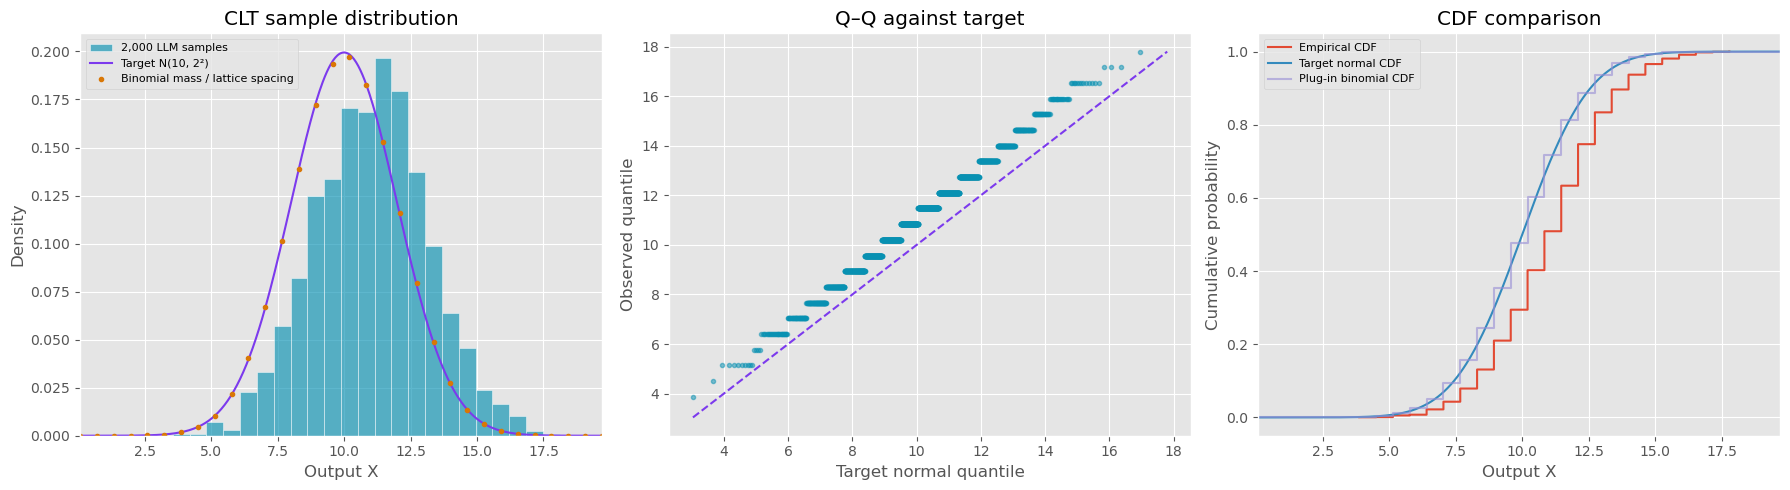

Status: 2,000 samples collected
Lattice spacing: 0.6328214085767296


In [6]:
if 'x' in samples and len(samples):
    x = samples.x.to_numpy()
    probabilities = [0.01,0.05,0.25,0.5,0.75,0.95,0.99]
    summary = pd.DataFrame({'observed': [len(x), np.mean(x), np.std(x,ddof=1),
                                          np.min(x),np.max(x)],
                            'target': [2000,10,2,-np.inf,np.inf]},
                           index=['n','mean','sample_std','min','max'])
    quantiles = pd.DataFrame({'probability': probabilities,
        'observed': np.quantile(x,probabilities),
        'target': stats.norm.ppf(probabilities,loc=10,scale=2)})
    display(summary)
    display(quantiles)
    production_p = float(selected.value.eq(1).mean())
    iid_sd_at_production_p = 2*math.sqrt(production_p*(1-production_p)/(p_hat*(1-p_hat)))
    variance_ratio = float(np.var(x, ddof=1)/iid_sd_at_production_p**2)
    display(Markdown(
        f'**Recorded result:** mean **{np.mean(x):.4f}**, standard deviation '
        f'**{np.std(x,ddof=1):.4f}**, versus target **10 and 2**. '
        f'The production +1 rate is {production_p:.6f}, versus frozen calibration '
        f'{p_hat:.3f}. The bias mismatch shifts the output mean. Under independent '
        f'flips at the observed production rate, the frozen transform would have '
        f'standard deviation {iid_sd_at_production_p:.4f}; observed variance is '
        f'{variance_ratio:.3f} times that reference. Bias mismatch alone does not '
        f'explain excess spread. Calibration noise, dependence, time variation and '
        f'backend routing require care; these diagnostics do not identify a cause.'))
    summary.to_csv(DATA / 'clt_sample_summary.csv', index_label='statistic')
    quantiles.to_csv(DATA / 'clt_sample_quantiles.csv', index=False)
    counts = np.arange(41)
    lattice = 10+2*((2*counts-40)-40*mu)/(math.sqrt(40)*sigma)
    mass = stats.binom.pmf(counts,40,p_hat)
    spacing = lattice[1]-lattice[0]
    visible = lattice[mass>1e-7]
    lo, hi = min(x.min(),visible.min(),3), max(x.max(),visible.max(),17)
    grid = np.linspace(lo,hi,500)
    with plt.style.context('ggplot'):
        fig, axes = plt.subplots(1,3,figsize=(18,5))
        edges = np.r_[lattice-spacing/2,lattice[-1]+spacing/2]
        axes[0].hist(x,bins=edges,density=True,color='#0891b2',alpha=.65,
                     edgecolor='white',label=f'{len(x):,} LLM samples')
        axes[0].plot(grid,stats.norm.pdf(grid,10,2),color='#7c3aed',label='Target N(10, 2²)')
        axes[0].plot(lattice,mass/spacing,'o',markersize=3,color='#d97706',
                     label='Binomial mass / lattice spacing')
        axes[0].set(xlim=(lo,hi),xlabel='Output X',ylabel='Density',title='CLT sample distribution')
        axes[0].legend(fontsize=8)
        ordered = np.sort(x)
        plotting_positions = (np.arange(len(x))+.5)/len(x)
        theoretical = stats.norm.ppf(plotting_positions,10,2)
        axes[1].plot(theoretical,ordered,'.',alpha=.5,color='#0891b2')
        limits = [min(theoretical.min(),ordered.min()),max(theoretical.max(),ordered.max())]
        axes[1].plot(limits,limits,'--',color='#7c3aed')
        axes[1].set(xlabel='Target normal quantile',ylabel='Observed quantile',title='Q–Q against target')
        axes[2].step(ordered,np.arange(1,len(x)+1)/len(x),where='post',label='Empirical CDF')
        axes[2].plot(grid,stats.norm.cdf(grid,10,2),label='Target normal CDF')
        axes[2].step(lattice,np.cumsum(mass),where='post',alpha=.6,label='Plug-in binomial CDF')
        axes[2].set(xlim=(lo,hi),xlabel='Output X',ylabel='Cumulative probability',title='CDF comparison')
        axes[2].legend(fontsize=8)
        fig.tight_layout()
        fig.savefig(DATA / 'clt_normal_diagnostics.png', dpi=180, bbox_inches='tight')
        plt.show()
    print('Status:', '2,000 samples collected' if len(x)==2000 else 'PARTIAL COLLECTION')
    print('Lattice spacing:', spacing)
else:
    print('No transformed samples available yet. No synthetic histogram is substituted.')

## Stability and dependence diagnostics

Compare calibration with production, examine consecutive blocks in **planned request order**, and report lag correlations for flips and final outputs. These are exploratory checks, not proofs of independence. A narrow confidence interval assumes independent Bernoulli observations. Invalid-group exclusion can itself select a different distribution, so all-valid-response and selected-group rates are both shown. Provider completion times are provenance, not the sequence used for analysis. The model and system fingerprint tables below expose routing strata: mixing backend configurations can violate an identical-distribution assumption. Fingerprints do not identify all possible backend differences, and matching fingerprints do not establish independence. Within-group fingerprint counts describe how often the 40 calls span recorded configurations.

,source,n,ones,p_hat,ci95_low,ci95_high
0,calibration,1000,517,0.517000,0.486022,0.547848
1,all production valid responses,80000,44621,0.557763,0.554318,0.561201
2,selected complete groups,80000,44621,0.557763,0.554318,0.561201


Calibration and production response rates by recorded model/fingerprint:


,phase,model,system_fingerprint,calls,valid,invalid,ones,p_hat,ci95_low,ci95_high
0,calibration,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,133,133,0,75,0.563910,0.479009,0.645222
1,calibration,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,867,867,0,442,0.509804,0.476559,0.542963
2,production,gpt-4.1-mini-2025-04-14,fp_8957c4f4dd,22883,22883,0,13142,0.574313,0.567895,0.580706
3,production,gpt-4.1-mini-2025-04-14,fp_92f9364fa2,57117,57117,0,31479,0.551132,0.547050,0.555207


Per-group routing provenance, ordered by immutable group ID:


,group_id,calls,known_fingerprints,missing_fingerprints,models,selected,fingerprints
0,0,40,2,0,1,True,fp_8957c4f4dd | fp_92f9364fa2
1,1,40,2,0,1,True,fp_8957c4f4dd | fp_92f9364fa2
2,2,40,2,0,1,True,fp_8957c4f4dd | fp_92f9364fa2
3,3,40,2,0,1,True,fp_8957c4f4dd | fp_92f9364fa2
4,4,40,1,0,1,True,fp_92f9364fa2
...,...,...,...,...,...,...,...
1995,1995,40,2,0,1,True,fp_8957c4f4dd | fp_92f9364fa2
1996,1996,40,2,0,1,True,fp_8957c4f4dd | fp_92f9364fa2
1997,1997,40,2,0,1,True,fp_8957c4f4dd | fp_92f9364fa2
1998,1998,40,2,0,1,True,fp_8957c4f4dd | fp_92f9364fa2


,selected,known_fingerprints,missing_fingerprints,groups
0,True,1,0,860
1,True,2,0,1140


,block,calls,valid,p_hat,ci95_low,ci95_high
0,0,1000,1000,0.570,0.539105,0.600359
1,1,1000,1000,0.563,0.532074,0.593444
2,2,1000,1000,0.561,0.530066,0.591467
3,3,1000,1000,0.594,0.563259,0.624021
4,4,1000,1000,0.527,0.496011,0.557782
...,...,...,...,...,...,...
75,75,1000,1000,0.582,0.551173,0.612199
76,76,1000,1000,0.555,0.524046,0.585533
77,77,1000,1000,0.560,0.529063,0.590478
78,78,1000,1000,0.528,0.497011,0.558775


,lag,flip_pairs,flip_correlation,output_correlation
0,1,79999,0.005591,0.056142
1,2,79998,0.002360,0.053001
2,5,79995,0.003383,0.019420
3,10,79990,0.003192,0.026545
4,40,79960,0.004398,0.038051
5,100,79900,-0.001331,0.018819


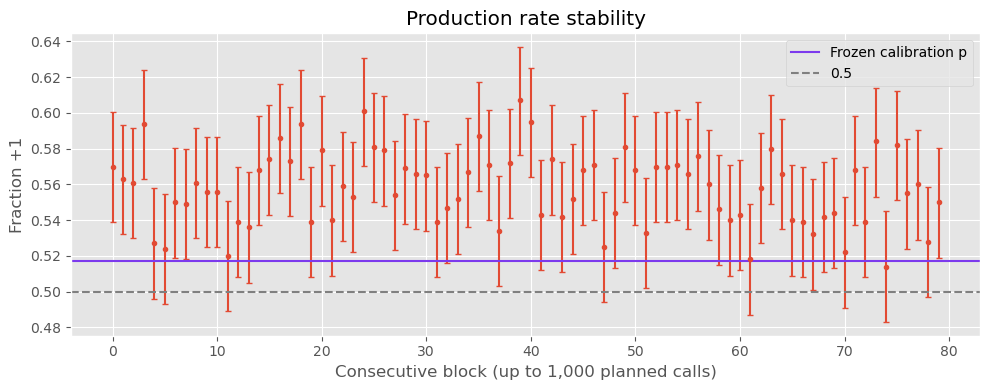

In [7]:
rate_rows = []
for name, frame in [('calibration',calibration),('all production valid responses',production),
                    ('selected complete groups',selected)]:
    valid = frame.loc[frame.parsed_binary_valid]
    ones, n = int(valid.value.eq(1).sum()),len(valid)
    low, high = wilson(ones,n)
    rate_rows.append(dict(source=name,n=n,ones=ones,p_hat=ones/n if n else np.nan,
                          ci95_low=low,ci95_high=high))
display(pd.DataFrame(rate_rows))

routing_rows = []
for phase_name, frame in [('calibration',calibration),('production',production)]:
    for (model, fingerprint), group in frame.groupby(
            ['model','system_fingerprint'],dropna=False,sort=False):
        valid = group.loc[group.parsed_binary_valid]
        n, ones = len(valid), int(valid.value.eq(1).sum())
        lo, hi = wilson(ones,n)
        routing_rows.append(dict(phase=phase_name, model=model,
            system_fingerprint=fingerprint, calls=len(group), valid=n,
            invalid=len(group)-n, ones=ones, p_hat=ones/n if n else np.nan,
            ci95_low=lo, ci95_high=hi))
routing_rates = pd.DataFrame(routing_rows)
print('Calibration and production response rates by recorded model/fingerprint:')
display(routing_rates)

fingerprint_rows = []
for group_id, group in production.groupby('group_id',sort=True):
    known_fingerprints = group.system_fingerprint.dropna().astype(str)
    fingerprint_rows.append(dict(group_id=int(group_id), calls=len(group),
        known_fingerprints=known_fingerprints.nunique(),
        missing_fingerprints=int(group.system_fingerprint.isna().sum()),
        models=group.model.nunique(dropna=True),
        selected=int(group_id) in accepted_ids,
        fingerprints=' | '.join(sorted(known_fingerprints.unique()))))
group_fingerprints = pd.DataFrame(fingerprint_rows)
print('Per-group routing provenance, ordered by immutable group ID:')
display(group_fingerprints)
if len(group_fingerprints):
    display(group_fingerprints.groupby(['selected','known_fingerprints',
                                        'missing_fingerprints']).size().rename('groups').reset_index())
    group_fingerprints.to_csv(DATA / 'clt_group_fingerprints.csv',index=False)
if len(routing_rates):
    routing_rates.to_csv(DATA / 'clt_routing_rates.csv',index=False)

ordered_prod = production.sort_values(['group_id','position']).copy()
ordered_prod['planned_block'] = np.arange(len(ordered_prod))//1000
blocks = []
for block_id, frame in ordered_prod.groupby('planned_block'):
    valid = frame.loc[frame.parsed_binary_valid]
    n, ones = len(valid),int(valid.value.eq(1).sum())
    lo,hi=wilson(ones,n)
    blocks.append(dict(block=int(block_id),calls=len(frame),valid=n,
                       p_hat=ones/n if n else np.nan,ci95_low=lo,ci95_high=hi))
block_rates=pd.DataFrame(blocks)
display(block_rates)
series = ordered_prod.value.where(ordered_prod.parsed_binary_valid).reset_index(drop=True)
lag_rows=[]
for lag in [1,2,5,10,40,100]:
    paired=pd.concat([series,series.shift(lag)],axis=1).dropna()
    flip_corr=paired.iloc[:,0].corr(paired.iloc[:,1]) if len(paired)>2 else np.nan
    sample_corr=samples.x.autocorr(lag) if 'x' in samples and len(samples)>lag+2 else np.nan
    lag_rows.append(dict(lag=lag,flip_pairs=len(paired),flip_correlation=flip_corr,
                         output_correlation=sample_corr))
display(pd.DataFrame(lag_rows))
if len(block_rates):
    with plt.style.context('ggplot'):
        fig,ax=plt.subplots(figsize=(10,4))
        ax.errorbar(block_rates.block,block_rates.p_hat,
                    yerr=[block_rates.p_hat-block_rates.ci95_low,
                          block_rates.ci95_high-block_rates.p_hat],fmt='.',capsize=2)
        if np.isfinite(p_hat):
            ax.axhline(p_hat,color='#7c3aed',label='Frozen calibration p')
        ax.axhline(.5,color='gray',linestyle='--',label='0.5')
        ax.set(xlabel='Consecutive block (up to 1,000 planned calls)',
               ylabel='Fraction +1',title='Production rate stability')
        ax.legend()
        fig.tight_layout()
        plt.show()

## Interpretation

A completed run contains 80,000 valid selected production flips, plus the prompt pilot, 1,000 calibration calls, excluded groups, and any transport retries. The CSV derivatives preserve request IDs; `responses.jsonl` and `attempts.jsonl` are the original audit records. The manifest records collection settings and progress.

Forty-flip sums may resemble a normal centrally while differing in their tails and discrete support. Calibration error can shift the entire distribution materially. Inspect the actual mean, standard deviation, quantiles, exact binomial reference, and stability diagnostics together; visual resemblance alone cannot establish independent normal sampling.